# Notebook 1: Herding with Monte Carlo learning

#### **The herding task**
We have a field (a grid) with a pen in the top-right corner. There is a sheep, and there are one or two dogs. The goal is to get the sheep into the pen. When the sheep is in the pen, the **episode ends**. This end goal is important, because the learning method we use in this notebook is monte carlo learning which updates after every episode (an episode needs a terminal state).

There is one more way an episode can end: after **200 steps** (`max_steps`). Then the dogs failed, and the episode stops anyway. We need this, because an untrained dog walks around randomly, and it could take a very long time before the sheep ends up in the pen by chance. With Monte Carlo that is a problem: the dog only learns at the end of an episode, so without a maximum length it might hardly learn anything for a long time.

The **sheep** is a rule-based agent, like the agents you have built in this course. If a dog comes close (within the *flee radius*), the sheep moves away from it. If no dog is close, the sheep mostly grazes and sometimes wanders a bit.

The sheep has a parameter `sheep_panic`. When a dog comes close, the sheep sometimes panics and sprints 2 cells away instead of 1 (`sheep_panic` is the chance that this happens) or it acts randomly (sprint or random is a flip of a coin, 50%). With `sheep_panic = 0` the sheep is calm. Note that this is a property of the sheep only: it says nothing about how many dogs there are.

The **dogs** have no rules for herding. They have to learn what to do from reward alone. Every step costs a little (-0.1), and getting the sheep into the pen gives a big reward (+10).

#### **Monte Carlo learning**
Each dog keeps a table Q(s, a): how much reward it expects in the long run if it does action *a* in state *s* (and then keeps going as usual).

Monte Carlo learning is the most direct way to fill this table: **play a whole episode, and then look back**. After the episode, for every step we compute the **return** G: the reward of that step plus all rewards that came after it, discounted with $\gamma$:

\begin{equation}
G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots
\end{equation}

Then we nudge our estimate towards what actually happened:

\begin{equation}
Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \, (G_t - Q(s_t, a_t))
\end{equation}

We use the **first-visit** version: if a dog was in the same state and did the same action several times in one episode, we only update it for the first time.

So the dog learns nothing *during* an episode. It has to wait until the episode is over, because only then does it know the return. That is why Monte Carlo needs an end goal.

#### **On-policy with $\epsilon$-greedy**
The dog mostly picks the action with the highest Q value, but with probability $\epsilon$ it does something random (exploration). The Q values the dog learns are the values of exactly this behaviour, exploration included. This is called **on-policy** learning: you learn about the policy you are actually following.

#### **What does a dog see?**
A dog's state *s* is: the position of the sheep on the field (x, y), and where the sheep is relative to the dog (dx, dy, cut off at 3 cells). A dog does **not** see the other dog. For each dog, the other dog is just part of its environment (but it cant observe the other).

So remember we have the following components:
* Number of dogs (1 or 2)
* Wheter the sheep makes panic jumps
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* Maximum length of an episode
* Number of training steps

# Lets get started

In [1]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
import copy

# the five things a dog can do: stay, right, left, up, down (as steps in x and y)
ACTIONS = [(0, 0), (1, 0), (-1, 0), (0, 1), (0, -1)]

# Agent setup: the sheep (rule-based)

In [2]:
class Sheep(CellAgent):
    """A rule-based sheep that flees from dogs.
    flee_radius: how close a dog must be before the sheep reacts
    sheep_panic: chance that a fleeing sheep panics and sprints 2 cells away instead of 1
                 (0 = calm sheep, higher = panics more easily)

    The sheep does not learn. It follows the same simple rules every step:
      1. a dog is close  -> flee (and sometimes panic and sprint)
      2. no dog is close -> mostly graze (stay put), sometimes wander a bit
    It is a CellAgent: it lives on a cell of the grid, and moves by switching to another cell.
    """
    def __init__(self, model, cell, flee_radius=2, sheep_panic=0.0):
        super().__init__(model)
        self.cell = cell                  # the cell the sheep starts on
        self.flee_radius = flee_radius
        self.sheep_panic = sheep_panic

    def distance_to_nearest_dog(self, position):
        """Distance (in steps, diagonal counts as one step) from a position to the nearest dog.

        We measure the distance as the largest of the x-distance and the y-distance
        (this is called the Chebyshev distance). So a dog 2 cells to the right and 1 cell up
        is at distance 2: it is within reach in 2 diagonal-ish steps.
        """
        # the positions of all dogs, as (x, y) coordinates
        dog_positions = [dog.cell.coordinate for dog in self.model.dogs]
        # for every dog: the distance to the position. Then take the smallest: the nearest dog
        return min(max(abs(position[0] - dx), abs(position[1] - dy)) for dx, dy in dog_positions)

    def step(self):
        x, y = self.cell.coordinate
        # where could the sheep go? (stay, or one step in four directions, but not off the field)
        # ACTIONS are the same five moves the dogs have: stay, right, left, up, down
        options = [(x + ax, y + ay) for ax, ay in ACTIONS if self.model.inside((x + ax, y + ay))]

        if self.distance_to_nearest_dog((x, y)) <= self.flee_radius:
            # a dog is close: flee.
            # for every option, how far would we be from the nearest dog? Find the biggest distance...
            best = max(self.distance_to_nearest_dog(p) for p in options)
            # ...and pick one of the options with that distance (at random, if there are several)
            target = self.model.random.choice([p for p in options if self.distance_to_nearest_dog(p) == best])
            # panic: sometimes the sheep sprints one cell further in the same direction.
            # (target - current position) is the step the sheep takes; adding it twice gives a 2-cell sprint
            if self.model.random.random() < self.sheep_panic:
                # 50% percent it sprints, 50% it just flees randomly.
                if self.model.random.random() < 0.5:
                    jump = (2 * target[0] - x, 2 * target[1] - y) # the cell 2 steps away in the same direction
                else:
                    jump = self.model.random.choice(options)      # just flee randomly
                if self.model.inside(jump):                   # only if the sprint stays on the field
                    target = jump
        elif self.model.random.random() > 0.2:
            target = (x, y)                                   # no dog close: mostly graze (stay put, 80% of the time)
        else:
            target = self.model.random.choice(options)        # and sometimes wander a bit (20% of the time)

        # move the sheep to its new cell
        self.cell = self.model.grid[target]

# Agent setup: the dog (Monte Carlo learning)
The dog has three important methods:
* `act()`: look at the state, pick an action ($\epsilon$-greedy), move, and **remember** the state and action
* `learn_from_episode()`: at the end of the episode, go **backwards** through the remembered steps, compute the return G, and update Q
* the Q-table itself is a dictionary: state -> one value per action

In [3]:
class Dog(CellAgent):
    """A dog that learns to herd with on-policy, first-visit Monte Carlo learning.
    alpha: learning rate (how far do we move our estimate towards the observed return)
    gamma: discount (how much do we care about rewards that come later)
    epsilon: exploration (how often do we do something random)

    How a Monte Carlo dog works:
      during an episode: look at the state, pick an action, move, and REMEMBER (state, action)
      at the end of the episode: look back at everything that happened, compute for every step
      the return G (all rewards that came after it), and move Q(state, action) towards G
    So during an episode the dog does not learn anything. It only collects experience.
    """
    def __init__(self, model, cell, alpha=0.1, gamma=0.95, epsilon=0.1):
        super().__init__(model)
        self.cell = cell                  # the cell the dog starts on
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True    # we can switch learning off (e.g., to test a trained dog)

        # The Q-table: a dictionary from state to an array with one value per action (5 actions).
        # Q[s][a] = how much reward the dog expects in the long run if it does action a in state s.
        # It starts empty and fills up as the dog meets new states.
        self.Q = {}

        # The memory of the current episode: a list of (state, action) pairs, one per step.
        # This is what the dog looks back on at the end of the episode.
        self.memory = []

    def observe(self):
        """The state: where is the sheep on the field, and where is the sheep relative to me?

        The state is a tuple of 4 numbers, e.g. (5, 2, -1, 3) means:
          the sheep is at x=5, y=2, and it is 1 cell to my left and 3 (or more) cells above me.
        """
        sx, sy = self.model.sheep.cell.coordinate     # where the sheep is
        x, y = self.cell.coordinate                   # where I am
        # relative position is cut off at 3 cells (np.clip keeps a number between -3 and 3):
        # "far to the right" is all the same to the dog. This keeps the number of states small
        return (sx, sy, int(np.clip(sx - x, -3, 3)), int(np.clip(sy - y, -3, 3)))

    def q_values(self, state):
        """Look up the Q values of a state. A state we have never seen starts at 0 for every action."""
        if state not in self.Q:
            self.Q[state] = np.zeros(len(ACTIONS))
        return self.Q[state]

    def act(self):
        """Pick an action with epsilon-greedy, move, and remember what we did."""
        state = self.observe()
        if self.model.random.random() < self.epsilon:
            action = self.model.random.randrange(len(ACTIONS))     # explore: random action
        else:
            q = self.q_values(state)                                 # exploit: best action so far
            # np.flatnonzero(q == q.max()) gives ALL actions with the highest value;
            # we pick one of those at random, so ties (e.g. all zeros in a new state) are broken fairly
            action = self.model.random.choice(np.flatnonzero(q == q.max()).tolist())
        self.memory.append((state, action))                          # remember for the end of the episode

        # do the move: ACTIONS[action] is a step in x and y, e.g. (1, 0) = one step to the right
        x, y = self.cell.coordinate
        new_position = (x + ACTIONS[action][0], y + ACTIONS[action][1])
        if self.model.inside(new_position): # dogs cannot leave the field, so we only update if the new position is still on the field
            self.cell = self.model.grid[new_position]

    def learn_from_episode(self, rewards):
        """Monte Carlo update at the end of an episode.
        rewards: the list of rewards of this episode (one per step, shared by all dogs).
                 rewards[t] is the reward that came right after the action in self.memory[t].
        """
        if self.learning:
            # first-visit: find the first time each (state, action) pair occurred in this episode.
            # setdefault only stores a value if the pair is not in the dictionary yet,
            # so we end up with the FIRST step t for every pair
            first_visit = {}
            for t, pair in enumerate(self.memory):
                first_visit.setdefault(pair, t)

            # Now we compute the return G for every step, by walking BACKWARDS through the episode.
            # The return of a step is: its own reward + gamma x the return of the next step.
            # Walking backwards, we can build this up step by step. 
            # So steps close to the success get a high return, steps far away a lower one.
            G = 0.0
            for t in range(len(self.memory) - 1, -1, -1):           # backwards! t = last step, ..., first step
                G = rewards[t] + self.gamma * G # the return of this step is its own reward + gamma x the return of the next step (remember we do this backwards, so G is the return of the next step)
                state, action = self.memory[t] # get the state and action of that led to the reward we just got
                if first_visit[(state, action)] == t:                # only update on the first visit
                    q = self.q_values(state) # select the state to update, and get its Q values (one per action)
                    # move the estimate a small step (alpha) towards the return we actually got for that action in that state
                    q[action] += self.alpha * (G - q[action])
        self.memory = []                                             # forget the episode, start fresh

# Model setup
One model step is: the dogs act, the sheep reacts, and we write down the reward. An **episode** ends when the sheep is in the pen (or after `max_steps`, then the dogs failed). At the end of an episode the dogs learn from everything that happened, and then the sheep and dogs are placed somewhere random again. The dogs keep their Q-tables, so over many episodes they get better.

The datacollector collects every step (the batch runner needs that). Next to that, the model keeps an `episode_log` with one row per episode, which we use for the learning curves.

In [4]:
class HerdingModel(mesa.Model):
    """The herding model: one sheep, one or two learning dogs, and a pen in the top-right corner.

    n_dogs: number of dogs (1 or 2)
    sheep_panic: chance that the fleeing sheep sprints 2 cells instead of 1 (0 = calm sheep)
    size: the field is size x size cells
    pen_size: the pen is pen_size x pen_size cells, in the top-right corner
    max_steps: maximum length of an episode (after that the dogs failed, and a new episode starts)
    flee_radius: how close a dog must be before the sheep reacts
    alpha, gamma, epsilon: the learning parameters, passed on to every dog
    """
    def __init__(self, n_dogs=1, sheep_panic=0.0, size=8, pen_size=2, max_steps=200,
                 flee_radius=2, alpha=0.1, gamma=0.95, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.size = size
        self.pen_size = pen_size
        self.max_steps = max_steps    # maximum length of one episode
        # the field: a grid of size x size cells. torus=False means the edges are walls
        # (walking off the right side does NOT bring you back on the left side)
        self.grid = OrthogonalMooreGrid((size, size), torus=False, random=self.random)

        # create the sheep and the dogs (at random places outside the pen)
        self.sheep = Sheep(self, self.random_cell(), flee_radius=flee_radius, sheep_panic=sheep_panic)
        # create_agents makes n_dogs dogs at once, each on its own random cell.
        # self.dogs is an AgentSet: a group of agents we can tell to do something together (e.g. self.dogs.do("act"))
        self.dogs = Dog.create_agents(self, n_dogs, [self.random_cell() for _ in range(n_dogs)],
                                      alpha=alpha, gamma=gamma, epsilon=epsilon)

        # bookkeeping
        self.t = 0                    # step within the current episode
        self.episode = 0              # number of finished episodes
        self.rewards = []             # rewards of the current episode (the dogs need these at the end of the episode)
        self.recent = deque(maxlen=200)   # (success, length) of the last 200 episodes; older ones drop out automatically
        self.recent_success_rate = 0      # share of the last 200 episodes in which the sheep was penned
        self.recent_episode_length = 0    # average number of steps of the last 200 episodes
        self.episode_log = []         # one row per episode, for the learning curves

        # Data collection!
        # The datacollector runs every step (the batch runner of our Mesa version needs that).
        # It only reads attributes that are updated at the end of every episode.
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "episode": "episode",
                "recent_success_rate": "recent_success_rate",
                "recent_episode_length": "recent_episode_length",
            }
        )

    def inside(self, position):
        """Is this position on the field? (used by the dogs and the sheep, so nobody walks off)"""
        return 0 <= position[0] < self.size and 0 <= position[1] < self.size

    def in_pen(self, position):
        """The pen is the top-right corner of the field.
        With size=8 and pen_size=2: x is 6 or 7, and y is 6 or 7."""
        return position[0] >= self.size - self.pen_size and position[1] >= self.size - self.pen_size

    def random_cell(self):
        """A random cell that is not in the pen. We need this for the initial positions of the sheep and the dogs.
        We keep drawing random positions until we find one outside the pen."""
        while True:
            position = (self.random.randrange(self.size), self.random.randrange(self.size))
            if not self.in_pen(position):
                return self.grid[position]

    def end_episode(self, success):
        """Called when the sheep is in the pen (success) or the time is up (no success)."""
        # 1. the dogs learn from the whole episode (this is the Monte Carlo part)
        #    every dog gets the same list of rewards (shared reward), but uses its own memory
        for dog in self.dogs:
            dog.learn_from_episode(self.rewards)
        # 2. bookkeeping
        self.recent.append((success, self.t))
        self.recent_success_rate = np.mean([s for s, l in self.recent])     # s = success (True/False), counts as 1/0
        self.recent_episode_length = np.mean([l for s, l in self.recent])   # l = length of the episode
        self.episode += 1
        self.episode_log.append({"episode": self.episode, "episode_length": self.t, "success": success})
        # 3. start a new episode: everything at a random place again (but the dogs keep their Q-tables)
        self.t = 0
        self.rewards = []
        self.sheep.cell = self.random_cell()
        for dog in self.dogs:
            dog.cell = self.random_cell()

    def step(self):
        """One model step: the dogs move, the sheep reacts, and we write down the reward."""
        self.dogs.do("act")           # every dog picks an action and moves (and remembers what it did)
        self.sheep.step()             # the sheep reacts
        self.t += 1

        # is the sheep in the pen? Then the episode is a success
        done = self.in_pen(self.sheep.cell.coordinate)
        # we only WRITE DOWN the reward here: the dogs learn from it at the end of the episode
        self.rewards.append(10.0 if done else -0.1)   # shared reward: all dogs get the same

        # the episode ends when the sheep is penned, or when the time is up
        if done or self.t >= self.max_steps:
            self.end_episode(success=done)
        self.datacollector.collect(self)   # every step (the batch runner needs this)

# Lets train some dogs
We train four set-ups for 600,000 steps each and look at the learning curves: how long does it take the dogs to pen the sheep, episode after episode? (This takes several minutes.)

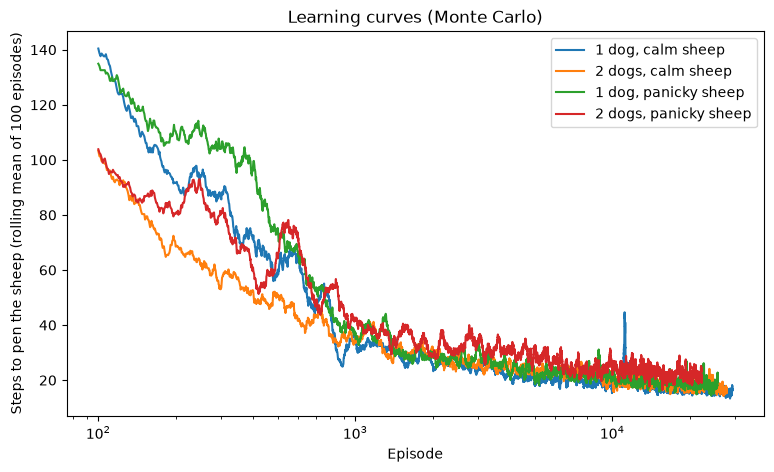

1 dog, calm sheep        success rate (last 200 episodes): 1.00
2 dogs, calm sheep       success rate (last 200 episodes): 1.00
1 dog, panicky sheep     success rate (last 200 episodes): 1.00
2 dogs, panicky sheep    success rate (last 200 episodes): 1.00


In [5]:
def train(n_steps=600_000, **params):
    """Make a model and run it for n_steps steps. Returns the trained model.
    The number of episodes is not fixed: it depends on how long the dogs take to pen the sheep. The more successful they are, the more episodes fit in n_steps."""
    model = HerdingModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

conditions = {
    "1 dog, calm sheep":    dict(n_dogs=1, sheep_panic=0.0),
    "2 dogs, calm sheep":   dict(n_dogs=2, sheep_panic=0.0),
    "1 dog, panicky sheep":  dict(n_dogs=1, sheep_panic=0.6),
    "2 dogs, panicky sheep": dict(n_dogs=2, sheep_panic=0.6),
}
# Train all four conditions (this takes a while, because each model runs for 600,000 steps)
trained = {name: train(rng=1, **params) for name, params in conditions.items()}


# plot the learning curves: rolling mean of the last 100 episodes, on a log scale (because the good dogs do many short episodes)
fig, ax = plt.subplots(figsize=(9, 5))
for name, model in trained.items():
    df = pd.DataFrame(model.episode_log)
    ax.plot(df["episode"], df["episode_length"].rolling(100).mean(), label=name)
ax.set_xscale("log")  # log scale, because the good dogs do many (short) episodes
ax.set_xlabel("Episode")
ax.set_ylabel("Steps to pen the sheep (rolling mean of 100 episodes)")
ax.set_title("Learning curves (Monte Carlo)")
ax.legend()
plt.show()

for name, model in trained.items():
    print(f"{name:24s} success rate (last 200 episodes): {model.recent_success_rate:.2f}")

# Make a custom visualization so we can watch the trained dogs
We pass a *trained* model to SolaraViz, so press play (not reset: reset makes a new, untrained model). We set exploration low (5%) so we mostly see what the dogs have learned.

In [ ]:
from matplotlib.patches import Rectangle

@solara.component
def HerdingVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()  # re-render when the model steps
    fig = plt.Figure(figsize=(6, 6))
    ax = fig.subplots()
    s, p = model.size, model.pen_size
    ax.add_patch(Rectangle((0, 0), s, s, facecolor="yellowgreen", alpha=0.3))          # the field
    ax.add_patch(Rectangle((s - p, s - p), p, p, facecolor="saddlebrown", alpha=0.4))  # the pen
    x, y = model.sheep.cell.coordinate
    ax.scatter(x + 0.5, y + 0.5, s=600, c="white", edgecolors="black", zorder=10)     # the sheep
    for i, dog in enumerate(model.dogs):                                               # the dogs
        dx, dy = dog.cell.coordinate
        ax.scatter(dx + 0.5, dy + 0.5, s=300, c=["black", "tab:orange"][i % 2], marker="s", zorder=10)
    ax.set_xlim(0, s)
    ax.set_ylim(0, s)
    ax.set_aspect("equal")
    ax.set_xticks(range(s + 1))
    ax.set_yticks(range(s + 1))
    ax.grid(True, alpha=0.3)
    ax.set_title(f"Episode {model.episode}, step {model.t}")
    solara.FigureMatplotlib(fig)

model = trained["2 dogs, panicky sheep"]   # try the other conditions too
for dog in model.dogs:
    dog.epsilon = 0.05 # what the dogs learned is already pretty good, so we can explore less now

page = SolaraViz(model, components=[HerdingVisualization], name="Herding with Monte Carlo")
page

Cannot show ipywidgets in text

# Batch run
Now all four set-ups, two runs each. For each run we look at the end of training: over the last 200 episodes, how often do the dogs succeed, and how many steps do they need? (This takes several minutes.)

  0%|          | 0/8 [00:00<?, ?it/s]

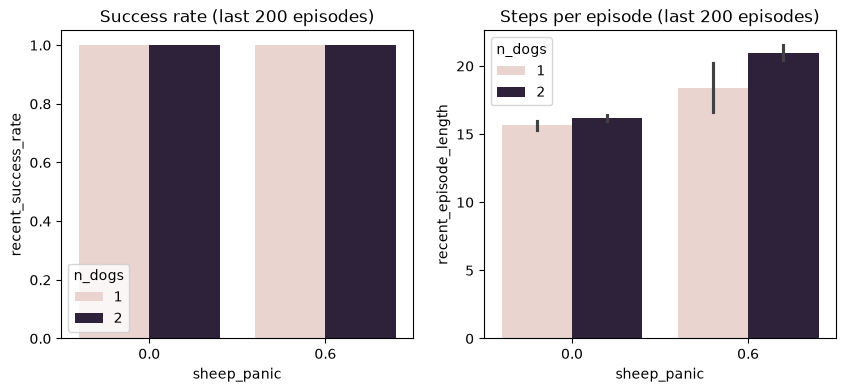

In [15]:
params = {"n_dogs": [1, 2],
          "sheep_panic": [0.0, 0.6]}

results = mesa.batch_run(
    HerdingModel,
    parameters=params,
    iterations=2,               # two runs per condition
    max_steps=600_000,
    number_processes=1,
    data_collection_period=-1,  # only collect at the end of the run
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./herding_mc_batch_run.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(results, x="sheep_panic", y="recent_success_rate", hue="n_dogs", ax=axes[0])
sns.barplot(results, x="sheep_panic", y="recent_episode_length", hue="n_dogs", ax=axes[1])
axes[0].set_title("Success rate (last 200 episodes)")
axes[1].set_title("Steps per episode (last 200 episodes)")
plt.show()

# Experiments for you
1. **Waiting for the end.** Monte Carlo only learns when an episode is over. Early in training, almost every episode ends after `max_steps` without success. What do the dogs learn from those episodes? Try `max_steps=100` and `max_steps=400`. What happens?
2. **First-visit or every-visit.** Change `learn_from_episode()` so it updates on *every* visit of a (state, action) pair. Does that change learning speed?
3. **Discount.** What happens with $\gamma = 0.5$? And with $\gamma = 1$? Why is the discount important for a dog that has to walk a long way before it gets any reward?
4. **Exploration.** Try $\epsilon = 0.01$ and $\epsilon = 0.3$. Remember that on-policy learning learns the value of the behaviour *including* the exploration. What does that mean for a dog that explores a lot?
5. **Does a second dog help?** In this task (pen in the corner), does a second dog help, or is it in the way? And does a panicky sheep make the task harder or easier here? Why?
6. **No end goal.** Imagine the pen is in the middle and the sheep can walk out again. There is no end of an episode anymore. Why does Monte Carlo learning not work then? (This is where the next notebook starts.)